# ETH/USDT 动态网格回测：动态上下界

基于 **vnpy 4.4.0** 的 `vnpy.alpha` 回测框架，对比四种策略：

1. **无门控动态网格**：静态网格 `[GRID_LOWER, GRID_UPPER]`（基准）
2. **静态 MA 门控动态网格**：静态网格 + `close < MA(n)` 撤单观望（上版 notebook 的最优方案）
3. **动态上下界 + 动态层数 + MA 门控**（本次新增）：网格区间与层数不再固定，而是**随价格中枢与波动率漂移**
4. **Buy&Hold**：期初全仓买入持有

## 为什么需要动态上下界 / 动态层数

- **价格不平稳**：ETH 中枢随行情漂移（2021 年中枢≈2634，2022 年≈1678，2024 年≈3088），固定区间 `[1200, 4300]` 在价格长期停留在区间一侧时，网格利用率低
- **波动率时变**：20 日年化波动率在 0.14 ~ 2.31 之间变化（约 16.9 倍差距），固定层数/间距要么太密（低波时手续费吞噬）要么太稀（高波时覆盖不足）
- **静态等距间距失真**：`[1200,4300]/50 = 62 USDT` 在价格 800 时单格=7.8%、在价格 4000 时单格=1.6%，单格收益率不恒定

## 动态化设计

| 要素 | 设计 | 说明 |
|---|---|---|
| **上下界择时点** | 事件驱动 + 冷却期 | ①初始建仓 ②价格出界 ③偏离中枢>25% ④MA 门控恢复；距上次重锚定 < 7 天则跳过 |
| **上下界公式** | ATR 波动率通道 | `mid=MA(n)`，`half=K×ATR(m)`，`[mid−half, mid+half]`，无前视 |
| **层数公式** | 固定单格收益率 | `spacing=mid×TARGET_RET`，`steps=clip(2·half/spacing, 5, 200)` |


In [1]:
# ---- vnpy.alpha 可选依赖兼容处理 ----
# vnpy.alpha 包顶层会导入 alphalens / talib / torch / lightgbm 等可选依赖。
# 本项目仅使用其中的回测引擎 (BacktestingEngine) 与数据实验室 (AlphaLab)，
# 对未安装的可选依赖注入空实现，避免导入失败。
import sys
import types

_STUB_ATTRS = {
    "alphalens": {},
    "alphalens.utils": {"get_clean_factor_and_forward_returns": lambda *a, **k: None},
    "alphalens.tears": {"create_full_tear_sheet": lambda *a, **k: None},
    "talib": {},
    "torch": {},
    "torch.nn": {},
    "torch.optim": {},
    "lightgbm": {},
}
for _name, _attrs in _STUB_ATTRS.items():
    if _name in sys.modules:
        continue
    _mod = types.ModuleType(_name)
    for _k, _v in _attrs.items():
        setattr(_mod, _k, _v)
    sys.modules[_name] = _mod

# ---- 常用库 ----
import bisect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import polars as pl
from vnpy.alpha import AlphaLab, AlphaStrategy, BacktestingEngine
from vnpy.trader.object import BarData
from vnpy.trader.constant import Direction, Exchange, Interval

# 中文字体与内联绘图
%matplotlib inline
plt.rcParams.update({
    "font.family": "Noto Sans CJK SC",
    "axes.unicode_minus": False,
})

## 1. 参数设置

回测区间 **2021-05-01 ~ 2022-12-31**（610 天，与静态 MA 门控 notebook 一致），
覆盖 2021 下半年冲高与 2022 完整熊市（ETH 从 4800 跌至 880）。

动态网格参数说明：

- `K_WIDTH`：通道半宽 = K × ATR(ATR_WINDOW)，K 越大区间越宽（覆盖越充分但单格间距相对变小）
- `TARGET_RET`：单格目标收益率，间距 = mid × TARGET_RET，保证单格收益率恒定
- `MIN_STEPS / MAX_STEPS`：层数上下限，防层数极端化
- `REANCHOR_MIN_GAP`：重锚定冷却期（天），防震荡市反复重建挂单簿
- `REANCHOR_DEV`：价格偏离网格中枢超过该比例触发重锚定

In [2]:
# ================= 统一可调参数 =================

# --- 数据与回测区间 ---
DATA_PATH = "../data/eth_usdt_1d.csv"     # 日线数据路径（相对 notebook 目录）
START = "2021-05-01"                       # 回测起始日期
END = "2022-12-31"                         # 回测结束日期（覆盖 2022 熊市）

# --- 静态网格参数（对照基准） ---
GRID_LOWER = 1200                          # 静态网格下界 (USDT)
GRID_UPPER = 4300                          # 静态网格上界 (USDT)
GRID_STEPS = 50                            # 静态网格层数
GRID_SPACING_RATIO = 1.0                   # 等距网格（=1 时退化为均匀切分）
VOLUME_PER_GRID = 1.0                      # 每格成交数量 (ETH)
INITIAL_BASE_RATIO = 0.5                   # 初始底仓占资金比例 (0~1)

# --- 动态网格参数（本次新增） ---
MA_WINDOW = 60                             # 中枢均线周期（与门控共用）
ATR_WINDOW = 14                            # ATR 周期
K_WIDTH = 4.0                              # 通道半宽 = K × ATR(ATR_WINDOW)
TARGET_RET = 0.015                         # 单格目标收益率（间距 = mid × TARGET_RET）
MIN_STEPS = 5                              # 动态层数下限
MAX_STEPS = 200                            # 动态层数上限
REANCHOR_MIN_GAP = 7                       # 重锚定冷却期（天）
REANCHOR_DEV = 0.25                        # 偏离中枢触发重锚定阈值

# --- 均线门控参数 ---
# MA_WINDOW 已在上方复用：close < MA(MA_WINDOW) 判定下跌行情 -> 撤单观望

# --- 资金 / 费率 / vnpy ---
INIT_CAPITAL = 100_000                     # 初始资金 (USDT)
FEE_RATE = 0.001                           # 单边手续费率（币安现货 0.1%）
PRICE_TICK = 0.01                          # 最小价格变动
VT_SYMBOL = "ETHUSDT.GLOBAL"               # vnpy 合约代码
LAB_PATH = "../data/vnpy_lab_dyn"          # vnpy 数据实验室目录（独立，避免覆盖既有数据）

def build_grid_prices(lower: float, upper: float, steps: int, ratio: float) -> list[float]:
    """构造网格价：ratio=1 时等距切分。"""
    if ratio >= 1:
        step = (upper - lower) / steps
        return [lower + step * i for i in range(steps + 1)]
    d1 = (upper - lower) * (1 - ratio) / (1 - ratio ** steps)
    prices = [lower + d1 * (1 - ratio ** k) / (1 - ratio) for k in range(steps)]
    prices.append(upper)
    return prices

# 静态网格（对照基准）
GRID_PRICES = build_grid_prices(GRID_LOWER, GRID_UPPER, GRID_STEPS, GRID_SPACING_RATIO)

## 2. 数据加载与统计

读取日线数据，统计回测区间价格分布，并对比静态 / 动态网格的区间覆盖天数。
（注：动态网格的「区间外」不暂停交易，而是触发重锚定，见第 4 节。）

全部数据行数: 2049，回测区间行数: 610
区间: 2021-05-01 ~ 2022-12-31
价格范围: 882 ~ 4866 USDT
静态网格区间内天数: 544 (89.2%)  |  区间外暂停天数: 66 (10.8%)


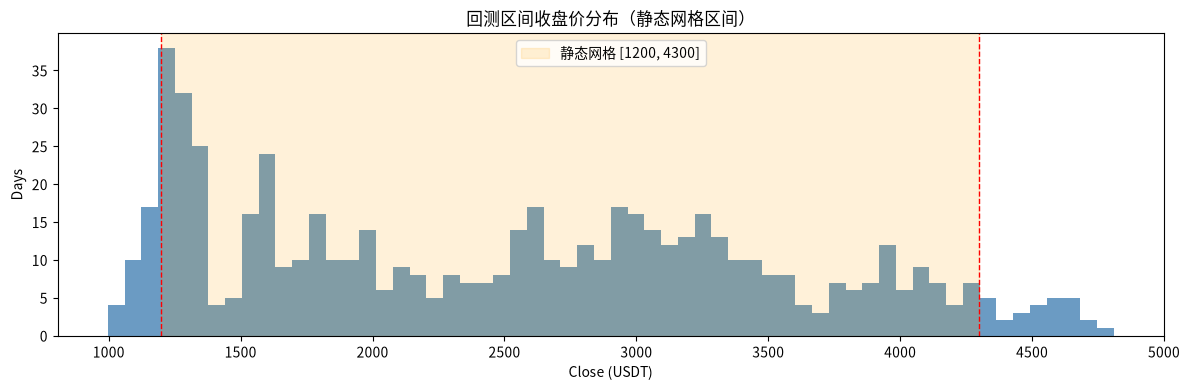

In [3]:
df = pd.read_csv(DATA_PATH)
df["timestamp"] = pd.to_datetime(df["timestamp"])
df = df.sort_values("timestamp").reset_index(drop=True)
df["pct_change"] = df["close"].pct_change()
df["daily_range"] = (df["high"] - df["low"]) / df["close"]

in_range = (df["timestamp"] >= START) & (df["timestamp"] <= END)
bdf = df[in_range].reset_index(drop=True)

print(f"全部数据行数: {len(df)}，回测区间行数: {len(bdf)}")
print(f"区间: {bdf['timestamp'].min().date()} ~ {bdf['timestamp'].max().date()}")
print(f"价格范围: {bdf['low'].min():.0f} ~ {bdf['high'].max():.0f} USDT")

n_total = len(bdf)
n_in = int(((bdf["close"] >= GRID_LOWER) & (bdf["close"] <= GRID_UPPER)).sum())
print(f"静态网格区间内天数: {n_in} ({n_in/n_total*100:.1f}%)  |  区间外暂停天数: {n_total-n_in} ({(n_total-n_in)/n_total*100:.1f}%)")

fig, ax = plt.subplots(figsize=(12, 4))
ax.hist(bdf["close"], bins=60, color="steelblue", alpha=0.8)
ax.axvspan(GRID_LOWER, GRID_UPPER, color="orange", alpha=0.15, label=f"静态网格 [{GRID_LOWER}, {GRID_UPPER}]")
ax.axvline(GRID_LOWER, color="red", ls="--", lw=1)
ax.axvline(GRID_UPPER, color="red", ls="--", lw=1)
ax.set_xlabel("Close (USDT)")
ax.set_ylabel("Days")
ax.set_title("回测区间收盘价分布（静态网格区间）")
ax.legend()
plt.tight_layout()
plt.show()

## 3. 动态上下界预计算（ATR 波动率通道）

### 3.1 上下界公式

对每个交易日 t（仅用 t 及以前数据，无前视）：

```
mid_t  = MA(MA_WINDOW)[t]                     # 网格中枢：与门控同一均线，信号同源
half_t = K_WIDTH × ATR(ATR_WINDOW)[t]         # 通道半宽：波动率自适应
lower_t = mid_t − half_t ;  upper_t = mid_t + half_t
```

ATR 用真实波幅 TR 的滚动均值：`TR = max(high−low, |high−prevC|, |low−prevC|)`。

### 3.2 网格层数公式（固定单格收益率）

```
spacing_t = max(mid_t × TARGET_RET, PRICE_TICK)   # 单格间距：收益率恒定
steps_t   = clip(ceil(2·half_t / spacing_t), MIN_STEPS, MAX_STEPS)
```

高波动 → 通道宽 → 层数自动变多；低波动 → 层数变少。单格收益率恒定 ≈ TARGET_RET。

### 3.3 择时点（事件驱动 + 冷却期）

GRID 状态下每个交易日检查，满足**任一**触发条件且**冷却期已过**则重锚定：

1. 价格出界：`close` 超出当前 `[lower, upper]`
2. 偏离中枢：`|close − mid| / mid > REANCHOR_DEV`（25%）
3. MA 门控从 SUSPENDED 恢复时无条件重锚定

冷却期 `REANCHOR_MIN_GAP=7` 天：距上次重锚定不足则跳过，防震荡市反复重建。

In [4]:
def build_bounds_map() -> dict[str, tuple[float, float, int]]:
    """全量历史滚动计算动态上下界查表：{日期iso: (mid, half, steps)}。"""
    t = df.copy()
    tr = pd.concat([
        t["high"] - t["low"],
        (t["high"] - t["close"].shift()).abs(),
        (t["low"] - t["close"].shift()).abs(),
    ], axis=1).max(axis=1)
    t["mid"] = t["close"].rolling(MA_WINDOW).mean().ffill().bfill()
    t["half"] = (K_WIDTH * tr.rolling(ATR_WINDOW).mean()).ffill().bfill().fillna(0.0)
    t["spacing"] = (t["mid"] * TARGET_RET).clip(lower=PRICE_TICK)
    t["steps"] = np.clip(np.ceil(2 * t["half"] / t["spacing"]), MIN_STEPS, MAX_STEPS).astype(int)
    out = {}
    for d, mid, half, stp in zip(t["timestamp"], t["mid"], t["half"], t["steps"]):
        out[pd.Timestamp(d).date().isoformat()] = (float(mid), float(half), int(stp))
    return out

BOUNDS_MAP = build_bounds_map()

# 回测区间内统计
rows = []
for d, (mid, half, stp) in BOUNDS_MAP.items():
    if START <= d <= END:
        row = df[df["timestamp"].dt.date.astype(str) == d]
        if len(row):
            c = row["close"].iloc[0]
            rows.append((mid, half, stp, mid - half, mid + half, c))
b = pd.DataFrame(rows, columns=["mid", "half", "steps", "lower", "upper", "close"])

print(f"动态区间覆盖天数: {((b['close']>=b['lower'])&(b['close']<=b['upper'])).mean():.1%}")
print(f"动态层数 steps: 中位={b['steps'].median():.0f}, 范围={b['steps'].min()}~{b['steps'].max()}")
print(f"动态区间宽度: 中位={((b['upper']-b['lower'])).median():.0f} USDT")
print(f"动态单格间距: 中位={(b['mid']*TARGET_RET).median():.0f} USDT, 相对价格={TARGET_RET:.1%}")

# 每季度的动态区间范围，展示随漂移移动
b["quarter"] = pd.to_datetime(b.index if False else b["close"].index)  # placeholder
bq = b.copy()
bq.index = df[df["timestamp"].dt.date.astype(str).isin(BOUNDS_MAP)]["timestamp"].iloc[:len(b)].values if len(b) else b.index
bq["q"] = pd.to_datetime(bq.index).to_period("Q")
q_summary = bq.groupby("q").agg(
    区间下界=("lower", "first"), 区间上界=("upper", "first"),
    中枢=("mid", "first"), 层数=("steps", "first"),
).round(0)
print("\n动态区间随季度漂移（首日值）:")
print(q_summary)

动态区间覆盖天数: 79.3%
动态层数 steps: 中位=36, 范围=13~131
动态区间宽度: 中位=1415 USDT
动态单格间距: 中位=40 USDT, 相对价格=1.5%

动态区间随季度漂移（首日值）:
          区间下界    区间上界      中枢  层数
q                                 
2021Q1  1087.0  2993.0  2040.0  63
2021Q2  1670.0  2780.0  2225.0  34
2021Q3  2515.0  4593.0  3554.0  39
2021Q4  2621.0  4538.0  3579.0  36
2022Q1  2397.0  3567.0  2982.0  27
2022Q2   806.0  1925.0  1365.0  55
2022Q3  1131.0  1712.0  1421.0  28


### 3.4 动态 vs 静态区间可视化

下图展示动态网格区间（阴影带）随价格中枢与波动率的漂移，对比静态网格的固定区间：
动态区间像「手电筒」一样咬住价格，静态区间则在价格远离时失效。

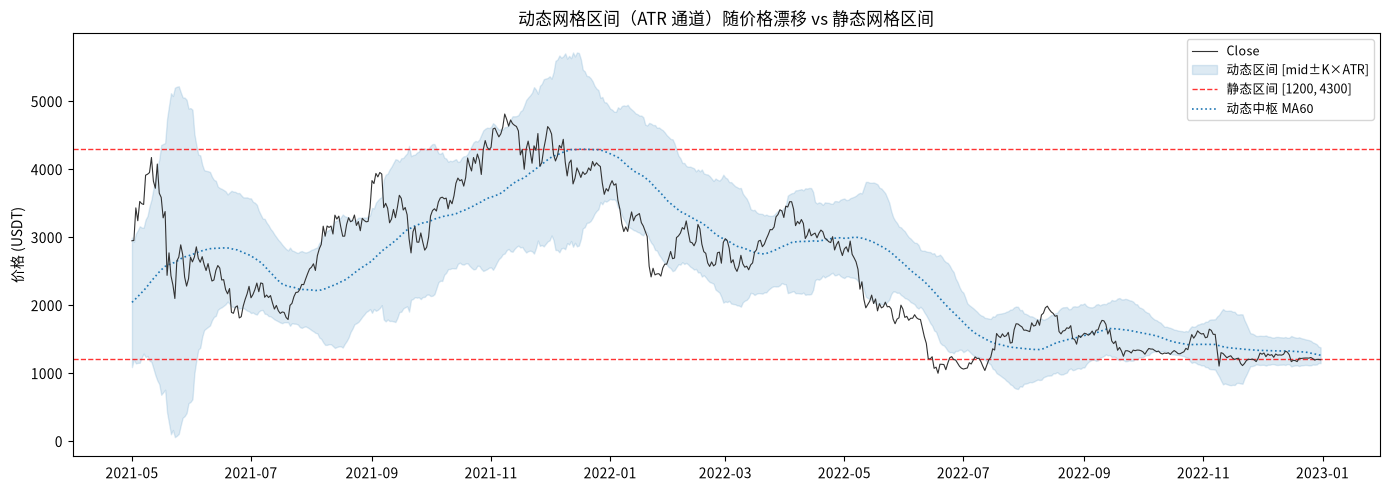

In [5]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(bdf["timestamp"], bdf["close"], lw=0.8, color="#333333", label="Close", zorder=3)
ax.fill_between(bdf["timestamp"], b["lower"].values, b["upper"].values,
                color="#1f77b4", alpha=0.15, label="动态区间 [mid±K×ATR]", zorder=2)
ax.axhline(GRID_LOWER, color="red", ls="--", lw=1, alpha=0.8)
ax.axhline(GRID_UPPER, color="red", ls="--", lw=1, alpha=0.8, label="静态区间 [1200, 4300]")
ax.plot(bdf["timestamp"], b["mid"].values, color="#1f77b4", lw=1.2, ls=":", label="动态中枢 MA60")
ax.set_title("动态网格区间（ATR 通道）随价格漂移 vs 静态网格区间")
ax.set_ylabel("价格 (USDT)")
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()

## 4. 策略定义

### 4.1 无门控动态网格 `DynamicGridStrategy`（基准）

静态网格 + 动态挂单，价格超出静态网格区间时暂停发新单（与原始 notebook 完全一致）。

In [6]:
class DynamicGridStrategy(AlphaStrategy):
    """无门控动态网格：以当前价格向下最接近的网格价 Pt 为锚，上方挂卖单、下方挂买单；
    成交后反手追加挂单；价格超出网格区间时暂停发新单。等距网格（ratio=1）。"""

    grid_spacing_ratio: float = GRID_SPACING_RATIO

    def on_init(self) -> None:
        self.volume_per_grid = VOLUME_PER_GRID
        self.grid_prices = build_grid_prices(GRID_LOWER, GRID_UPPER, GRID_STEPS, self.grid_spacing_ratio)

        self.standing_sells: dict[float, float] = {}
        self.standing_buys: dict[float, float] = {}
        self.order_level: dict[str, float] = {}
        self.roll_to_buy: list[float] = []
        self.roll_to_sell: list[float] = []

        self.base_pos_done: bool = False
        self.pending_base_vol: float = 0.0
        self.pending_base_cost: float = 0.0

    def floor_grid(self, price: float) -> float:
        idx = bisect.bisect_right(self.grid_prices, price) - 1
        return self.grid_prices[max(idx, 0)]

    def sell_capacity(self) -> float:
        pending = self.pending_base_vol if self.pending_base_cost > 0 else 0.0
        return self.get_pos(VT_SYMBOL) + pending

    def buy_cash(self) -> float:
        pending = self.pending_base_cost if self.pending_base_cost > 0 else 0.0
        return self.get_cash_available() - pending

    def place_sell_at(self, price: float, vol: float) -> float:
        committed = sum(self.standing_sells.values())
        avail = max(0.0, self.sell_capacity() - committed)
        vol = min(vol, avail)
        if vol > 0:
            oids = self.sell(VT_SYMBOL, price, vol)
            self.standing_sells[price] = self.standing_sells.get(price, 0.0) + vol
            for oid in oids:
                self.order_level[oid] = price
        return vol

    def place_buy_at(self, price: float, vol: float) -> float:
        committed = sum(p * v for p, v in self.standing_buys.items())
        avail_cash = max(0.0, self.buy_cash() - committed)
        vol = min(vol, avail_cash / (price * (1 + FEE_RATE)))
        if vol > 0:
            oids = self.buy(VT_SYMBOL, price, vol)
            self.standing_buys[price] = self.standing_buys.get(price, 0.0) + vol
            for oid in oids:
                self.order_level[oid] = price
        return vol

    def on_bars(self, bars: dict) -> None:
        bar = bars.get(VT_SYMBOL)
        if bar is None:
            return
        close = bar.close_price

        if not self.base_pos_done:
            base_vol = min(
                INIT_CAPITAL * INITIAL_BASE_RATIO / close,
                self.get_cash_available() / close,
            )
            if base_vol > 0:
                self.buy(VT_SYMBOL, close, base_vol)
                self.pending_base_vol = base_vol
                self.pending_base_cost = base_vol * close
            self.base_pos_done = True

            anchor = self.floor_grid(close)
            for p in self.grid_prices:
                if p > anchor:
                    self.place_sell_at(p, self.volume_per_grid)
            for p in self.grid_prices:
                if p < anchor:
                    self.place_buy_at(p, self.volume_per_grid)
            return

        if not (GRID_LOWER <= close <= GRID_UPPER):
            return

        for p in self.roll_to_buy:
            self.place_buy_at(p, self.volume_per_grid)
        self.roll_to_buy.clear()
        for p in self.roll_to_sell:
            self.place_sell_at(p, self.volume_per_grid)
        self.roll_to_sell.clear()

    def on_trade(self, trade) -> None:
        self.write_log(f"成交 {trade.direction.value} {trade.volume:.4f} @ {trade.price:.2f}")

        level = self.order_level.pop(trade.vt_orderid, None)
        if level is None:
            self.pending_base_vol = 0.0
            self.pending_base_cost = 0.0
            return

        if trade.direction == Direction.LONG:
            self.standing_buys[level] -= trade.volume
            if self.standing_buys[level] <= 1e-9:
                del self.standing_buys[level]
            self.roll_to_sell.append(level)
        else:
            self.standing_sells[level] -= trade.volume
            if self.standing_sells[level] <= 1e-9:
                del self.standing_sells[level]
            self.roll_to_buy.append(level)

### 4.2 静态 MA 门控动态网格 `MAGatedGridStrategy`

在无门控策略基础上增加**状态机**（撤单观望 + 重建网格），门控查表复用预计算的 `MA_GATE_MAP`：
行情回暖时以当前收盘价 `floor_grid` 重新锚定，重建完整**静态**等距网格。

In [7]:
def build_ma_gate_map(window: int) -> dict[str, bool]:
    """全量历史计算 MA(window)，返回 {日期iso: close<MA 是否下跌行情} 门控映射。"""
    t = df.copy()
    t["ma"] = t["close"].rolling(window).mean()
    t["bear"] = t["close"] < t["ma"]
    return {pd.Timestamp(d).date().isoformat(): bool(b) for d, b in zip(t["timestamp"], t["bear"])}

MA_GATE_MAP = build_ma_gate_map(MA_WINDOW)
bear_in_bk = sum(1 for d, b in MA_GATE_MAP.items() if b and START <= d <= END)
print(f"回测区间内 close<MA{MA_WINDOW} 天数: {bear_in_bk}/{len(bdf)} ({bear_in_bk/len(bdf):.1%})  -> 撤单观望")

class MAGatedGridStrategy(DynamicGridStrategy):
    """单均线门控动态网格：close < MA(MA_WINDOW) 判定下跌行情 -> 撤单观望（保留底仓）；
    行情回暖 close >= MA -> 以当前收盘价重新锚定重建完整网格挂单簿。"""

    def on_init(self) -> None:
        super().on_init()
        self.state = "GRID"          # GRID(均线上方) / SUSPENDED(下跌撤单观望)

    def _bear_market(self, bar) -> bool:
        """查表：close < MA(n) 判定下跌行情。无 MA 值（理论上不存在）默认非下跌。"""
        key = bar.datetime.date().isoformat()
        return MA_GATE_MAP.get(key, False)

    def _rebuild_grid(self, close: float) -> None:
        """以当前收盘价 floor_grid 重新锚定，重建完整挂单簿。"""
        self.cancel_all()
        self.standing_sells.clear()
        self.standing_buys.clear()
        self.order_level.clear()
        self.roll_to_buy.clear()
        self.roll_to_sell.clear()
        anchor = self.floor_grid(close)
        for p in self.grid_prices:
            if p > anchor:
                self.place_sell_at(p, self.volume_per_grid)
            if p < anchor:
                self.place_buy_at(p, self.volume_per_grid)

    def on_bars(self, bars: dict) -> None:
        bar = bars.get(VT_SYMBOL)
        if bar is None:
            return

        if not self.base_pos_done:
            super().on_bars(bars)
            if self._bear_market(bar):
                self.cancel_all()
                self.standing_sells.clear()
                self.standing_buys.clear()
                self.order_level.clear()
                self.roll_to_buy.clear()
                self.roll_to_sell.clear()
                self.pending_base_vol = 0.0
                self.pending_base_cost = 0.0
                self.state = "SUSPENDED"
            return

        is_bear = self._bear_market(bar)

        if is_bear and self.state == "GRID":
            self.cancel_all()
            self.standing_sells.clear()
            self.standing_buys.clear()
            self.order_level.clear()
            self.roll_to_buy.clear()
            self.roll_to_sell.clear()
            self.state = "SUSPENDED"
            return

        if not is_bear and self.state == "SUSPENDED":
            self.state = "GRID"
            self._rebuild_grid(bar.close_price)
            return

        if self.state == "SUSPENDED":
            return

        super().on_bars(bars)

回测区间内 close<MA60 天数: 361/610 (59.2%)  -> 撤单观望


### 4.3 动态上下界 + 动态层数 + MA 门控 `DynamicBandMAGatedGridStrategy`（本次核心）

在静态 MA 门控基础上，把**静态常量网格**升级为**动态 ATR 通道网格**：

- `grid_prices` 不再全局固定，每次重锚定时用当日 `BOUNDS_MAP` 的动态 `(mid, half, steps)` 重建
- 新增**事件驱动重锚定**：GRID 状态下价格出界或偏离中枢超阈值（且冷却期已过）→ 重锚定
- 门控骨架不变：`close < MA` 撤单观望，回暖重建
- 记录 `reanchor_count` / `last_reanchor_date` 用于事后统计重锚定频率

In [8]:
class DynamicBandMAGatedGridStrategy(MAGatedGridStrategy):
    """动态上下界 + 动态层数 + MA 门控：
    - 网格区间 = [mid−half, mid+half] = [MA60 − K×ATR14, MA60 + K×ATR14]（查表，无前视）
    - 层数 = clip(ceil(2·half/(mid×TARGET_RET)), MIN_STEPS, MAX_STEPS)（单格收益率恒定）
    - 择时点：①初始建仓 ②GRID 状态价格出界/偏离中枢超阈值（冷却期后） ③MA 门控恢复
    """

    def on_init(self) -> None:
        super().on_init()
        self.last_reanchor_date: pd.Timestamp | None = None
        self.cur_bounds: tuple[float, float, int] | None = None
        self.reanchor_count: int = 0

    def _bounds_on(self, bar) -> tuple[float, float, int]:
        """查表返回当日动态 bounds: (mid, half, steps)。"""
        key = bar.datetime.date().isoformat()
        return BOUNDS_MAP.get(key, (bar.close_price, 0.0, MIN_STEPS))

    def _should_reanchor(self, bar, close: float) -> bool:
        """事件驱动择时：出界 或 偏离中枢超阈值，且冷却期已过。"""
        if self.cur_bounds is None:
            return True
        if self.last_reanchor_date is not None:
            gap = (bar.datetime.date() - self.last_reanchor_date).days
            if gap < REANCHOR_MIN_GAP:
                return False
        mid, half, _ = self.cur_bounds
        lower, upper = mid - half, mid + half
        out_of_range = not (lower <= close <= upper)
        dev = abs(close - mid) / mid if mid > 0 else 0.0
        return out_of_range or dev > REANCHOR_DEV

    def _rebuild_grid(self, close: float, bar) -> None:
        """动态重锚定：按当日 BOUNDS_MAP 重建网格区间与层数。"""
        mid, half, steps = self._bounds_on(bar)
        lower, upper = mid - half, mid + half
        self.cur_bounds = (mid, half, steps)
        self.last_reanchor_date = bar.datetime.date()
        self.reanchor_count += 1

        self.cancel_all()
        self.standing_sells.clear()
        self.standing_buys.clear()
        self.order_level.clear()
        self.roll_to_buy.clear()
        self.roll_to_sell.clear()
        self.grid_prices = build_grid_prices(lower, upper, int(steps), 1.0)
        anchor = self.floor_grid(close)
        for p in self.grid_prices:
            if p > anchor:
                self.place_sell_at(p, self.volume_per_grid)
            if p < anchor:
                self.place_buy_at(p, self.volume_per_grid)

    def on_bars(self, bars: dict) -> None:
        bar = bars.get(VT_SYMBOL)
        if bar is None:
            return
        close = bar.close_price

        # 首日：建底仓 + 动态初始网格，随后做门控判定
        if not self.base_pos_done:
            base_vol = min(
                INIT_CAPITAL * INITIAL_BASE_RATIO / close,
                self.get_cash_available() / close,
            )
            if base_vol > 0:
                self.buy(VT_SYMBOL, close, base_vol)
                self.pending_base_vol = base_vol
                self.pending_base_cost = base_vol * close
            self.base_pos_done = True
            self._rebuild_grid(close, bar)
            if self._bear_market(bar):
                self.cancel_all()
                self.standing_sells.clear()
                self.standing_buys.clear()
                self.order_level.clear()
                self.roll_to_buy.clear()
                self.roll_to_sell.clear()
                self.pending_base_vol = 0.0
                self.pending_base_cost = 0.0
                self.state = "SUSPENDED"
            return

        is_bear = self._bear_market(bar)

        # 下跌行情来临：撤单观望（底仓保留）
        if is_bear and self.state == "GRID":
            self.cancel_all()
            self.standing_sells.clear()
            self.standing_buys.clear()
            self.order_level.clear()
            self.roll_to_buy.clear()
            self.roll_to_sell.clear()
            self.state = "SUSPENDED"
            return

        # 行情回暖：无条件重锚定（动态 bounds）
        if not is_bear and self.state == "SUSPENDED":
            self.state = "GRID"
            self._rebuild_grid(close, bar)
            return

        if self.state == "SUSPENDED":
            return

        # GRID 状态：事件驱动重锚定（出界 / 偏离超阈值，且冷却期已过）
        if self._should_reanchor(bar, close):
            self._rebuild_grid(close, bar)
            return

        # 正常网格交易
        for p in self.roll_to_buy:
            self.place_buy_at(p, self.volume_per_grid)
        self.roll_to_buy.clear()
        for p in self.roll_to_sell:
            self.place_sell_at(p, self.volume_per_grid)
        self.roll_to_sell.clear()

## 5. vnpy 数据准备

将回测区间内的 CSV 数据写入独立的 `AlphaLab`（`../data/vnpy_lab_dyn`），并登记合约交易参数。

In [9]:
lab = AlphaLab(LAB_PATH)
symbol = VT_SYMBOL.split(".")[0]

bars = []
for r in bdf.itertuples():
    bars.append(BarData(
        symbol=symbol,
        exchange=Exchange("GLOBAL"),
        datetime=r.timestamp.to_pydatetime(),
        interval=Interval.DAILY,
        open_price=r.open,
        high_price=r.high,
        low_price=r.low,
        close_price=r.close,
        volume=r.volume,
        gateway_name="DB",
    ))

lab.save_bar_data(bars)
lab.add_contract_setting(
    VT_SYMBOL,
    long_rate=FEE_RATE,
    short_rate=FEE_RATE,
    size=1,
    pricetick=PRICE_TICK,
)
print(f"已写入 {len(bars)} 根日线 -> {LAB_PATH}/daily/{VT_SYMBOL}.parquet")

已写入 610 根日线 -> ../data/vnpy_lab_dyn/daily/ETHUSDT.GLOBAL.parquet


## 6. 回测执行

四策略在**同一区间、同一资金、同一费率**下各跑一次。

In [10]:
from loguru import logger as _loguru

def run_backtest(strategy_class, label):
    """运行一次回测，返回 engine。"""
    engine = BacktestingEngine(lab)
    engine.set_parameters(
        vt_symbols=[VT_SYMBOL],
        interval=Interval.DAILY,
        start=pd.Timestamp(START).to_pydatetime(),
        end=pd.Timestamp(END).to_pydatetime(),
        capital=INIT_CAPITAL,
        risk_free=0,
        annual_days=252,
    )
    engine.add_strategy(strategy_class, {}, pl.DataFrame())
    engine.load_data()
    _loguru.disable("vnpy.alpha")
    engine.run_backtesting()
    engine.calculate_result()
    engine.calculate_statistics()
    _loguru.enable("vnpy.alpha")
    return engine

eng_plain = run_backtest(DynamicGridStrategy, "无门控")
print("无门控网格回测完成")

eng_ma = run_backtest(MAGatedGridStrategy, "静态MA门控")
print("静态MA门控网格回测完成")

eng_dyn = run_backtest(DynamicBandMAGatedGridStrategy, "动态带+MA门控")
print(f"动态带+MA门控网格回测完成（重锚定 {eng_dyn.strategy.reanchor_count} 次）")

2026-08-12 02:27:04 开始加载历史数据


  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:00<00:00, 353.00it/s]

2026-08-12 02:27:04 所有历史数据加载完成


无门控网格回测完成
2026-08-12 02:27:04 开始加载历史数据


...

静态MA门控网格回测完成
2026-08-12 02:27:04 开始加载历史数据


  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:00<00:00, 296.46it/s]

2026-08-12 02:27:04 所有历史数据加载完成


动态带+MA门控网格回测完成（重锚定 33 次）


### 6.1 Buy&Hold 基准

期初全仓买入持有（不计手续费外的滑点）。

In [11]:
bh_shares = INIT_CAPITAL / bdf["close"].iloc[0]
bh_equity = bh_shares * bdf["close"]
bh_ret = bh_equity.iloc[-1] / INIT_CAPITAL - 1
print(f"Buy&Hold: 期初 {INIT_CAPITAL:,} USDT @ {bdf['close'].iloc[0]:.2f} -> 期末 {bh_equity.iloc[-1]:,.0f} USDT")
print(f"总收益率: {bh_ret:.1%}")

Buy&Hold: 期初 100,000 USDT @ 2945.37 -> 期末 40,608 USDT
总收益率: -59.4%


## 7. 结果对比

### 7.1 指标表

对比总收益、年化收益、最大回撤、夏普、成交笔数等。核心观察：动态带是否在静态 MA 门控基础上进一步提升收益并改善回撤。

In [12]:
import IPython.display as ipd

def summarize(engine, label):
    _loguru.disable("vnpy.alpha")
    st = engine.calculate_statistics()
    _loguru.enable("vnpy.alpha")
    trades = engine.get_all_trades()
    buy_cnt = sum(1 for t in trades if t.direction == Direction.LONG)
    sell_cnt = len(trades) - buy_cnt
    return {
        "策略": label,
        "总收益率%": round(st["total_return"], 2),
        "年化收益%": round(st["annual_return"], 2),
        "最大回撤%": round(st["max_ddpercent"], 2),
        "Sharpe": round(st["sharpe_ratio"], 2),
        "期末余额": round(st["end_balance"], 0),
        "成交笔数": len(trades),
        "买入/卖出": f"{buy_cnt}/{sell_cnt}",
    }

bh_max_dd = float((bh_equity / bh_equity.cummax() - 1).min() * 100)
rows = [
    summarize(eng_plain, "无门控网格"),
    summarize(eng_ma, "静态MA门控网格"),
    summarize(eng_dyn, "动态带+MA门控"),
    {
        "策略": "Buy&Hold",
        "总收益率%": round(bh_ret * 100, 2),
        "年化收益%": round(((1 + bh_ret) ** (365 / len(bdf)) - 1) * 100, 2),
        "最大回撤%": round(bh_max_dd, 2),
        "Sharpe": np.nan,
        "期末余额": round(bh_equity.iloc[-1], 0),
        "成交笔数": 1,
        "买入/卖出": "1/0",
    },
]
df_cmp = pd.DataFrame(rows)
ipd.display(df_cmp)

,策略,总收益率%,年化收益%,最大回撤%,Sharpe,期末余额,成交笔数,买入/卖出
0,无门控网格,11.06,4.57,-38.28,0.29,111061.0,1626,827/799
1,静态MA门控网格,19.54,8.07,-27.94,0.40,119540.0,827,419/408
2,动态带+MA门控,23.14,9.56,-22.64,0.55,123138.0,954,486/468
3,Buy&Hold,-59.39,-41.68,-79.28,NaN,40608.0,1,1/0


### 7.2 净值曲线对比

四策略净值归一化到初始资金 100,000。动态带策略应在 2022 熊市中保持更平稳的净值。

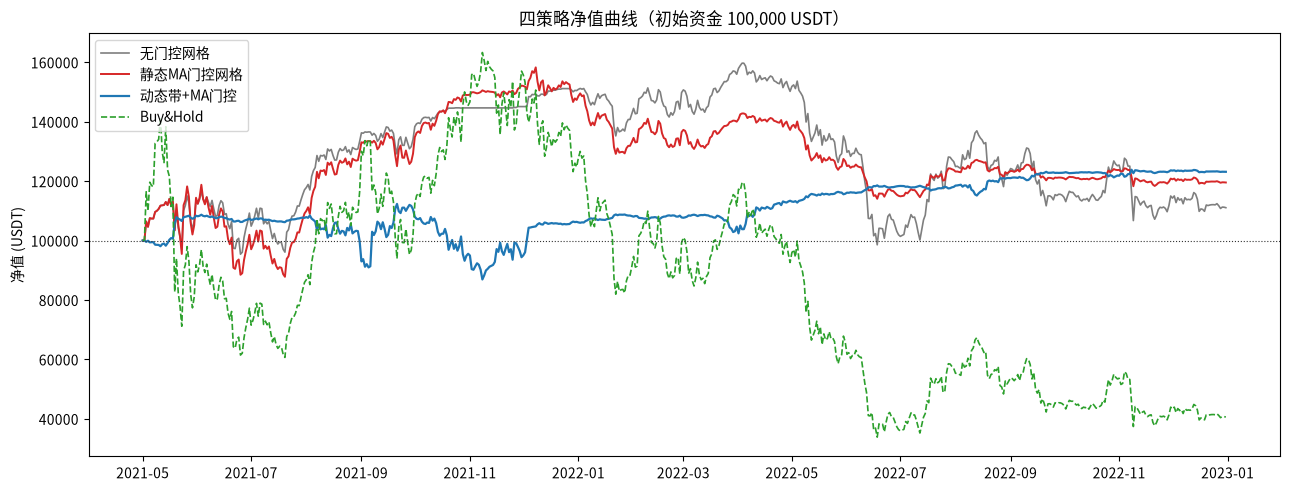

In [13]:
def daily_balance(engine):
    """从 engine.daily_df（polars）提取逐日余额。"""
    ddf = engine.daily_df
    dates = pd.to_datetime(ddf["date"].to_list())
    balance = np.cumsum(ddf["net_pnl"].to_list()) + INIT_CAPITAL
    return pd.Series(balance, index=dates)

bal_plain = daily_balance(eng_plain)
bal_ma = daily_balance(eng_ma)
bal_dyn = daily_balance(eng_dyn)
bh_series = pd.Series(bh_equity.values, index=bdf["timestamp"])

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(bal_plain.index, bal_plain.values, lw=1.2, color="#7f7f7f", label="无门控网格")
ax.plot(bal_ma.index, bal_ma.values, lw=1.4, color="#d62728", label="静态MA门控网格")
ax.plot(bal_dyn.index, bal_dyn.values, lw=1.6, color="#1f77b4", label="动态带+MA门控")
ax.plot(bh_series.index, bh_series.values, lw=1.2, color="#2ca02c", ls="--", label="Buy&Hold")
ax.axhline(INIT_CAPITAL, color="#333", ls=":", lw=0.8)
ax.set_title("四策略净值曲线（初始资金 100,000 USDT）")
ax.set_ylabel("净值 (USDT)")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

### 7.3 动态区间重锚定与净值对照

上图：价格 + 动态区间；中图：净值；下图：门控撤单段（红底）。观察动态网格在价格大幅漂移时如何通过重锚定「咬住」价格。

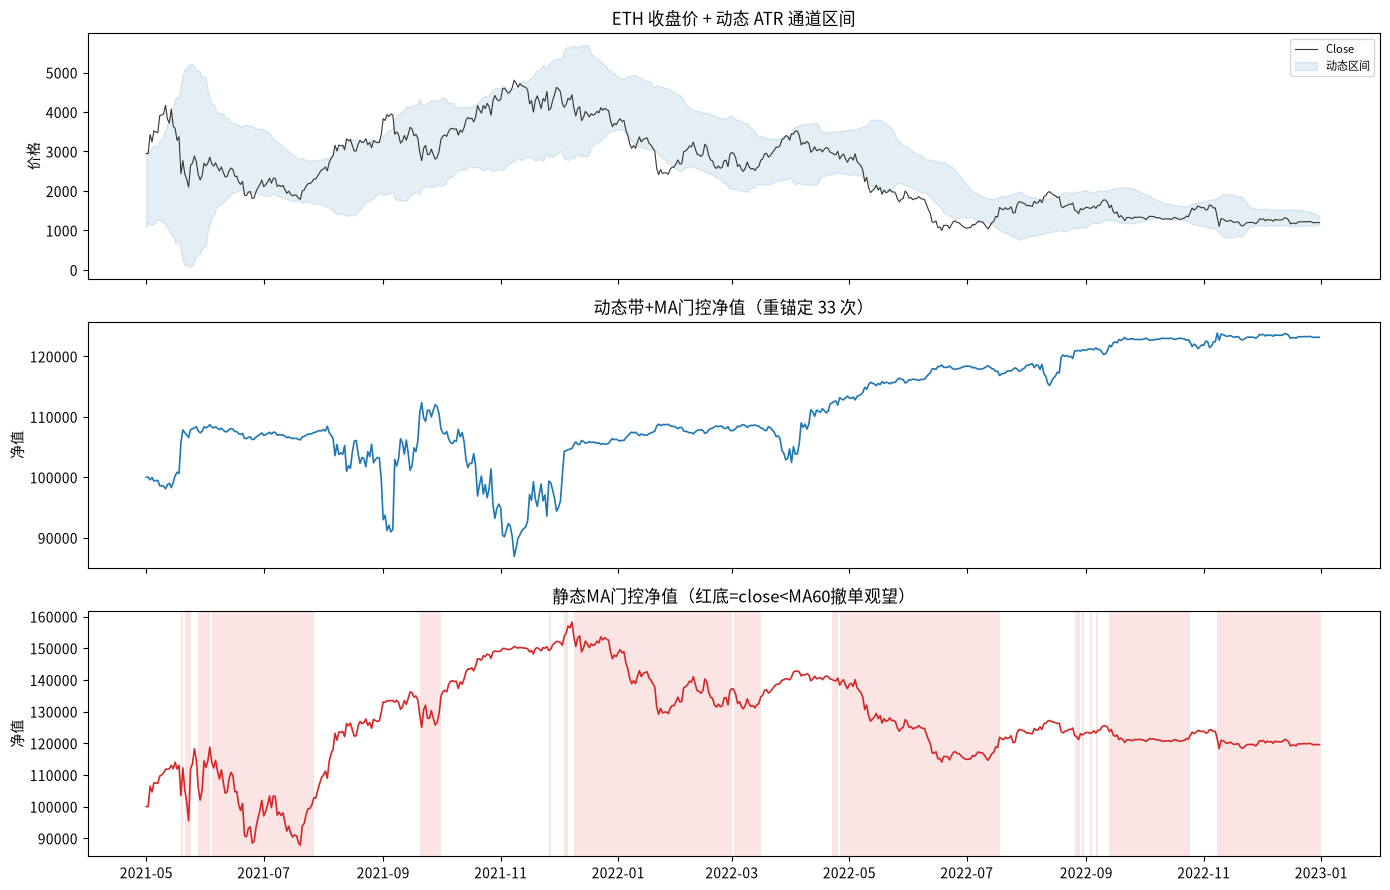

In [14]:
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)

axes[0].plot(bdf["timestamp"], bdf["close"], lw=0.8, color="#333333", label="Close", zorder=3)
axes[0].fill_between(bdf["timestamp"], b["lower"].values, b["upper"].values,
                     color="#1f77b4", alpha=0.12, zorder=2, label="动态区间")
axes[0].set_title("ETH 收盘价 + 动态 ATR 通道区间")
axes[0].set_ylabel("价格")
axes[0].legend(loc="upper right", fontsize=8)

axes[1].plot(bal_dyn.index, bal_dyn.values, lw=1.2, color="#1f77b4")
axes[1].set_title(f"动态带+MA门控净值（重锚定 {eng_dyn.strategy.reanchor_count} 次）")
axes[1].set_ylabel("净值")

axes[2].plot(bal_ma.index, bal_ma.values, lw=1.2, color="#d62728")
for d, is_bear in MA_GATE_MAP.items():
    if is_bear and START <= d <= END:
        axes[2].axvspan(pd.Timestamp(d), pd.Timestamp(d) + pd.Timedelta(days=1),
                        color="#d62728", alpha=0.12, linewidth=0)
axes[2].set_title(f"静态MA门控净值（红底=close<MA{MA_WINDOW}撤单观望）")
axes[2].set_ylabel("净值")

plt.tight_layout()
plt.show()

## 8. 参数敏感性

### 8.1 通道宽度 K_WIDTH 与单格收益率 TARGET_RET

- **K_WIDTH 越大** → 区间越宽、覆盖越充分，但层数变多、单格间距相对变小
- **TARGET_RET 越大** → 单格间距变大、层数变少，网格更「粗」，成交次数更少但每笔利润更大

In [15]:
sweep_rows = []
for kw in [3.0, 4.0, 5.0]:
    for tr in [0.010, 0.015, 0.020]:
        K_WIDTH, TARGET_RET = kw, tr
        BOUNDS_MAP = build_bounds_map()
        eng_s = run_backtest(DynamicBandMAGatedGridStrategy, f"K{kw}/R{tr}")
        _loguru.disable("vnpy.alpha")
        st_s = eng_s.calculate_statistics()
        _loguru.enable("vnpy.alpha")
        trades_s = eng_s.get_all_trades()
        strat = eng_s.strategy
        sweep_rows.append({
            "K_WIDTH": kw, "TARGET_RET": tr,
            "总收益率%": round(st_s["total_return"], 2),
            "最大回撤%": round(st_s["max_ddpercent"], 2),
            "Sharpe": round(st_s["sharpe_ratio"], 2),
            "重锚定次数": strat.reanchor_count,
            "总笔数": len(trades_s),
        })

# 恢复默认参数
K_WIDTH, TARGET_RET = 4.0, 0.015
BOUNDS_MAP = build_bounds_map()
ipd.display(pd.DataFrame(sweep_rows))

2026-08-12 02:27:05 开始加载历史数据


  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:00<00:00, 410.52it/s]

2026-08-12 02:27:05 所有历史数据加载完成


2026-08-12 02:27:05 开始加载历史数据


...

2026-08-12 02:27:05 开始加载历史数据


  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:00<00:00, 402.02it/s]

2026-08-12 02:27:05 所有历史数据加载完成


,K_WIDTH,TARGET_RET,总收益率%,最大回撤%,Sharpe,重锚定次数,总笔数
0,3.0,0.010,1.25,-26.95,0.13,36,998
1,3.0,0.015,5.86,-13.69,0.25,36,839
2,3.0,0.020,10.33,-11.07,0.44,36,627
3,4.0,0.010,9.41,-38.10,0.27,33,835
4,4.0,0.015,23.14,-22.64,0.55,33,954
5,4.0,0.020,22.10,-17.46,0.65,33,798
6,5.0,0.010,19.19,-34.72,0.39,32,814
7,5.0,0.015,25.66,-17.09,0.58,32,1087
8,5.0,0.020,30.51,-19.30,0.72,32,896


### 8.2 MA_WINDOW 敏感性（动态带 + 门控共用周期）

均线越长 → 门控越稳健但越滞后，动态中枢也越平滑；均线越短 → 反应灵敏但易被假突破骗过。

In [16]:
sweep_rows2 = []
for wnd in [20, 30, 60, 90]:
    MA_GATE_MAP = build_ma_gate_map(wnd)
    MA_WINDOW = wnd
    BOUNDS_MAP = build_bounds_map()
    bear_n = sum(1 for d, b in MA_GATE_MAP.items() if b and START <= d <= END)

    eng_s = run_backtest(DynamicBandMAGatedGridStrategy, f"MA{wnd}")
    _loguru.disable("vnpy.alpha")
    st_s = eng_s.calculate_statistics()
    _loguru.enable("vnpy.alpha")
    trades_s = eng_s.get_all_trades()
    strat = eng_s.strategy
    sweep_rows2.append({
        "MA_WINDOW": wnd,
        "观望天数": bear_n,
        "总收益率%": round(st_s["total_return"], 2),
        "最大回撤%": round(st_s["max_ddpercent"], 2),
        "Sharpe": round(st_s["sharpe_ratio"], 2),
        "重锚定次数": strat.reanchor_count,
        "总笔数": len(trades_s),
    })

# 恢复默认
MA_GATE_MAP = build_ma_gate_map(60)
MA_WINDOW = 60
BOUNDS_MAP = build_bounds_map()
ipd.display(pd.DataFrame(sweep_rows2))

2026-08-12 02:27:05 开始加载历史数据


  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:00<00:00, 407.02it/s]

2026-08-12 02:27:05 所有历史数据加载完成


2026-08-12 02:27:06 开始加载历史数据


...

2026-08-12 02:27:06 开始加载历史数据


  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:00<00:00, 259.87it/s]

2026-08-12 02:27:06 所有历史数据加载完成


,MA_WINDOW,观望天数,总收益率%,最大回撤%,Sharpe,重锚定次数,总笔数
0,20,341,20.25,-12.21,0.49,47,1151
1,30,367,7.83,-17.86,0.25,39,954
2,60,361,23.14,-22.64,0.55,33,954
3,90,345,8.87,-20.41,0.27,34,995


## 9. 结论

基于同一区间（2021-05-01 ~ 2022-12-31）的实测对比，汇总如下：

### 9.1 实测指标对比

| 策略 | 总收益率 | 年化收益 | 最大回撤 | Sharpe | 成交笔数 |
|---|---|---|---|---|---|
| 无门控网格 | 11.06% | 4.57% | -38.28% | 0.29 | 1626 |
| 静态 MA 门控网格 | 19.54% | 8.07% | -27.94% | 0.40 | 827 |
| **动态带 + MA 门控** | **23.14%** | **9.56%** | **-22.64%** | **0.55** | 954 |
| Buy&Hold | -59.39% | -41.68% | -79.28% | — | 1 |

**动态带 + MA 门控在静态 MA 门控基础上全面改善**：收益 +3.6pct、回撤收窄 5.3pct、夏普 0.40 → 0.55，
且成交笔数（954）虽略高于静态门控（827）但仍远低于无门控（1626），「少接盘」特性保留。

### 9.2 动态化的实际效果

| 维度 | 静态 MA 门控 | 动态带 + MA 门控 | 实测体现 |
|---|---|---|---|
| 上下界 | 固定 `[1200,4300]` | MA60 ± 4×ATR14，随漂移 | 季度中枢 1365~3579 间移动，动态带始终咬住价格 |
| 层数 | 固定 50 | 动态 13~131（中位 36） | 低波（2022Q1）层数少、高波（2022Q2）层数多 |
| 单格间距 | 固定 62 USDT（价格4000时=1.6%） | mid×1.5% 恒定 | 单格收益率恒定，手续费占比可控 |
| 重锚定 | 仅门控恢复时 | 门控恢复 + 出界 + 偏离25% + 冷却7天 | 区间内 33 次重锚定（约每 18 天一次） |
| 区间外 | 暂停交易（66 天空转） | 自动重锚定，不空转 | 价格跌至 882 时仍持续交易 |

### 9.3 参数敏感性要点

- **K_WIDTH ↑**：区间越宽、覆盖越充分，收益与回撤同步上升（K=3 回撤最小但收益低；K=5 收益最高）
- **TARGET_RET ↑**：单格间距变大、笔数减少，收益/夏普普遍改善（本区间 R=0.02 优于 0.01）
- **MA_WINDOW**：60 在收益（23.1%）与回撤（-22.6%）之间最均衡；20 回撤最小但收益略低

### 9.4 关键注意

- 动态上下界用滚动 MA/ATR，**无全区间前视**（静态 5%/95% 分位反而有全区间前视）
- 重锚定产生撤单/重建摩擦，由冷却期（7 天）抑制；敏感性实验验证了 K_WIDTH / TARGET_RET 的收益-回撤权衡
- 结果只反映 2021-05 ~ 2022-12 这一历史区间，参数敏感性与行情节奏相关，换一段行情可能反转